In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

# ==========================================================
# 1. Генерация и обоснование набора данных (1000 призывников)
# ==========================================================
# Моделируем 5 категорий согласно Расписанию болезней:
# 0 - "Годен" (А)
# 1 - "Годен с незначит. ограничениями" (Б)
# 2 - "Ограниченно годен" (В)
# 3 - "Временно не годен" (Г - например, временный недовес/давление)
# 4 - "Не годен" (Д - тяжелые нарушения)

n = 200

feature_names = [
    "BMI",
    "Vision_Diopters",
    "Systolic_BP",
    "Flatfoot_Degree",
    "Chronic_Index",
]
category_names = [
    "Годен (А)",
    "Годен с ограничениями (Б)",
    "Ограниченно годен (В)",
    "Временно не годен (Г)",
    "Не годен (Д)",
]

# Категория А (Идеал)
cat_A = np.column_stack(
    [
        np.random.normal(22, 1.5, n),
        np.random.normal(-0.2, 0.3, n),
        np.random.normal(120, 5, n),
        np.random.choice([0, 1], n, p=[0.8, 0.2]),
        np.random.exponential(0.3, n),
    ]
)

# Категория Б (Незначительные отклонения)
cat_B = np.column_stack(
    [
        np.random.normal(24, 2.0, n),
        np.random.normal(-2.0, 0.8, n),
        np.random.normal(128, 6, n),
        np.random.choice([1, 2], n, p=[0.6, 0.4]),
        np.random.normal(1.8, 0.5, n),
    ]
)

# Категория В (Освобождение в мирное время: плоскостопие 3 ст, зрение <-6 и т.д.)
cat_V = np.column_stack(
    [
        np.random.normal(27, 3.0, n),
        np.random.normal(-6.5, 1.2, n),
        np.random.normal(145, 8, n),
        np.random.choice([2, 3], n, p=[0.2, 0.8]),
        np.random.normal(4.5, 1.0, n),
    ]
)

# Категория Г (Временная негодность: острый недовес/ожирение, высокое давление)
cat_G = np.column_stack(
    [
        np.random.choice(
            [16.5, 36.0], n
        ),  # Острый дефицит или избыток веса
        np.random.normal(-3.5, 1.5, n),
        np.random.normal(155, 10, n),
        np.random.choice([1, 2], n, p=[0.5, 0.5]),
        np.random.normal(5.5, 1.2, n),
    ]
)

# Категория Д (Полная негодность: тяжелые декомпенсированные патологии)
cat_D = np.column_stack(
    [
        np.random.normal(32, 4.0, n),
        np.random.normal(-10.0, 2.0, n),
        np.random.normal(175, 12, n),
        np.random.choice([2, 3], n, p=[0.1, 0.9]),
        np.random.normal(8.5, 1.0, n),
    ]
)

X_raw = np.vstack([cat_A, cat_B, cat_V, cat_G, cat_D])
y_true = np.repeat([0, 1, 2, 3, 4], n)


df = pd.DataFrame(X_raw, columns=feature_names)
df["True_Category"] = [category_names[i] for i in y_true]

print(df.head(5))

         BMI  Vision_Diopters  Systolic_BP  Flatfoot_Degree  Chronic_Index  \
0  22.745071        -0.092664   112.027862              0.0       0.271218   
1  21.792604        -0.031765   117.003125              0.0       0.015839   
2  22.971533         0.124915   120.026218              0.0       0.205772   
3  24.284545         0.116141   120.234903              0.0       0.272529   
4  21.648770        -0.613301   117.749673              0.0       0.122050   

  True_Category  
0     Годен (А)  
1     Годен (А)  
2     Годен (А)  
3     Годен (А)  
4     Годен (А)  


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[feature_names])

In [ ]:
k = 5
kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)

df['Cluster'] = cluster_labels

In [ ]:
sil_score = silhouette_score(X_scaled, cluster_labels)
db_score = davies_bouldin_score(X_scaled, cluster_labels)
ari_score = adjusted_rand_score(y_true, cluster_labels)

print("\n--- МЕТРИКИ КАЧЕСТВА КЛАСТЕРИЗАЦИИ ---")
print(f"Silhouette Score (Силуэт, от -1 до 1, чем выше, тем лучше): {sil_score:.4f}")
print(f"Davies-Bouldin Index (чем ниже, тем компактнее кластеры):     {db_score:.4f}")
print(f"Adjusted Rand Index (сходство с исходными категориями 0..1): {ari_score:.4f}")


--- МЕТРИКИ КАЧЕСТВА КЛАСТЕРИЗАЦИИ ---
Silhouette Score (Силуэт, от -1 до 1, чем выше, тем лучше): 0.4950
Davies-Bouldin Index (чем ниже, тем компактнее кластеры):     0.7587
Adjusted Rand Index (сходство с исходными категориями 0..1): 0.7028


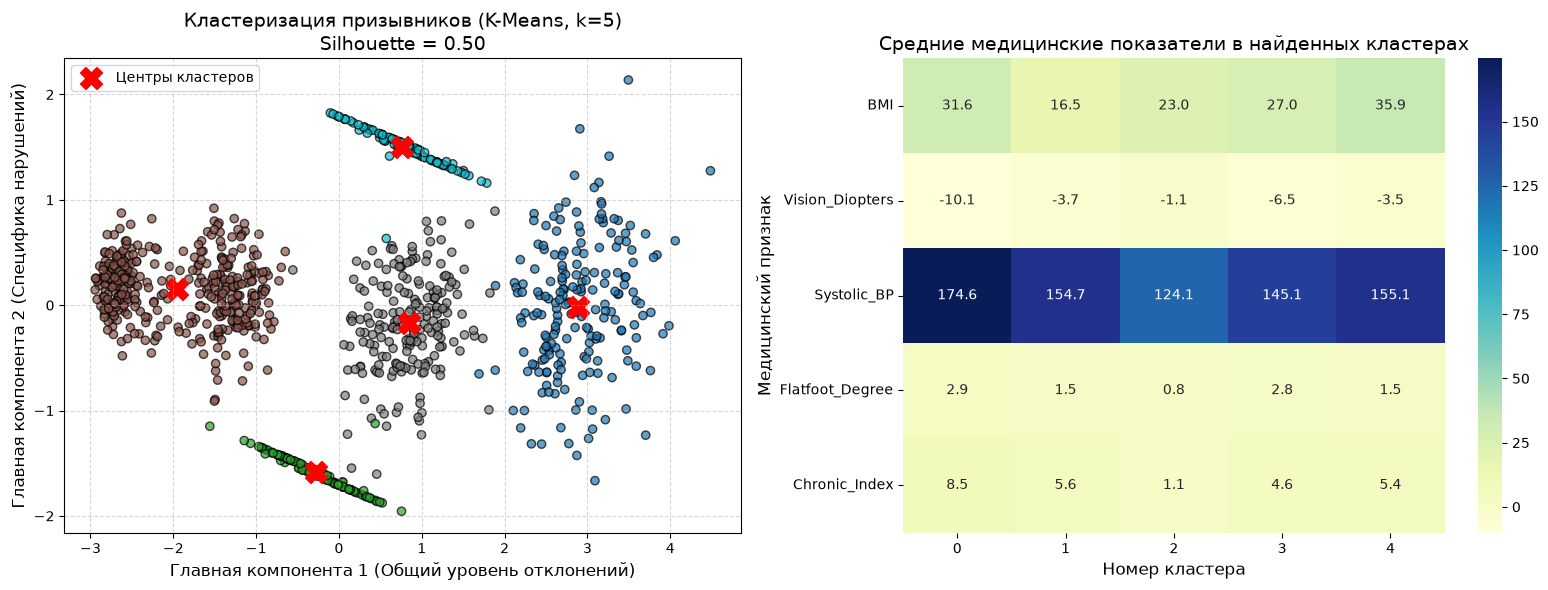

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# График 1: 2D проекция через PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

scatter = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='tab10', alpha=0.7, edgecolors='k')
# Центры кластеров
centers_pca = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', s=250, marker='X', label='Центры кластеров')

axes[0].set_title(f'Кластеризация призывников (K-Means, k=5)\nSilhouette = {sil_score:.2f}', fontsize=14)
axes[0].set_xlabel('Главная компонента 1 (Общий уровень отклонений)', fontsize=12)
axes[0].set_ylabel('Главная компонента 2 (Специфика нарушений)', fontsize=12)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# График 2: Портрет (профиль) каждого кластера
# Считаем средние реальные медицинские показатели для каждого кластера
cluster_profile = df.groupby('Cluster')[feature_names].mean()

sns.heatmap(cluster_profile.T, annot=True, fmt='.1f', cmap='YlGnBu', ax=axes[1])
axes[1].set_title('Средние медицинские показатели в найденных кластерах', fontsize=14)
axes[1].set_xlabel('Номер кластера', fontsize=12)
axes[1].set_ylabel('Медицинский признак', fontsize=12)

plt.tight_layout()
plt.show()

In [13]:
# ==========================================================
# 6. Интерпретация: сопоставление кластеров с категориями
# ==========================================================
print("\n--- СОПОСТАВЛЕНИЕ КЛАСТЕРОВ С КАТЕГОРИЯМИ ВОЕНКОМАТА ---")
print(pd.crosstab(df['Cluster'], df['True_Category']))


--- СОПОСТАВЛЕНИЕ КЛАСТЕРОВ С КАТЕГОРИЯМИ ВОЕНКОМАТА ---


KeyError: 'Cluster'